## Setup and model

The opening cells import NumPy for arrays and calculations and Matplotlib for plots, then set shared figure styling. The parameter cell defines gravity, trim speed, lift and drag coefficients, and the initial speed, angle, position, and altitude used throughout the examples.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# Set the font family and size to use for Matplotlib figures.
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 12

In [5]:
# Model parameters.
g = 9.81         # gravitational acceleration (m/s**2)
v_t = 4.9        # trim speed (m/s)
C_D = 1.0 / 5.0  # drag coefficient
C_L = 1.0        # lift coefficient

# Initial conditions.
v_0 = 6.5       # initial speed, above the trim speed (m/s)
theta_0 = -0.1  # trajectory angle (rad)
x_0 = 0.0       # horizontal position (m)
y_0 = 2.0       # altitude (m)

## Load the phugoid model

This cell retrieves the course-provided `phugoid.py` module, and the next imports its right-hand-side equations, Euler stepper, and discrete L1 difference helper. The download requires network access when the file is not already available.

In [6]:
from urllib.request import urlretrieve

url = (
    'https://raw.githubusercontent.com/'
    'numerical-mooc/practical-numerical-methods/main/'
    'src/phugoid.py'
)
fname = 'phugoid.py'
urlretrieve(url, fname)

('phugoid.py', <http.client.HTTPMessage at 0x7f0c3bb8cf50>)

In [7]:
from phugoid import (
    discrete_l1_difference,
    euler_step,
    rhs_full_phugoid,
)

## Define a second-order stepper

`rk2_step` implements the explicit midpoint Runge–Kutta method. It estimates the state at the midpoint using the initial slope, then uses the midpoint slope to advance one full time step.

In [8]:
def rk2_step(u,f,dt, *args):
    '''Return the next state using the secord-order Runge-Kutta method.

        Parameters
        ----------
        u : np.ndarray
            State at the current time
            as a 1D array of floats.
        f : function
            Function to compute the right-hand side of the system.
        dt : float
            Time-step size.
        *args
            Additional positional arguments passed to f.

        Returns
        -------
        u_new : np.ndarray
            The solution at the time step
            as a 1D array of floats.
        '''
    u_star = u + 0.5 * dt * f(u, *args)
    u_new = u + dt * f(u_star, *args)
    return u_new

## Compare Euler and RK2 trajectories

The notebook advances the same initial state over a common two-second interval with both Euler and RK2, storing every state on the same time grid. The next cells extract position histories, print final altitudes, and plot the paths and horizontal separation.

In [9]:
T_trajectory = 2.0 #common pre-impact interval (s)
dt = 0.01 #time-step size (s)
num_steps = int(round(T_trajectory / dt))

#Stpre the state at every point, including the initial state.
u_euler = np.empty((num_steps + 1, 4))
u_rk2 = np.empty((num_steps + 1, 4))
u_euler[0] = np.array([v_0, theta_0, x_0, y_0])
u_rk2[0] = np.array([v_0, theta_0, x_0, y_0])

# Advance both methods over the same time grid.
for n in range(num_steps):
    u_euler[n+1] = euler_step(
        u_euler[n], rhs_full_phugoid, dt, C_L, C_D, g, v_t
    )
    u_rk2[n + 1] = rk2_step(
        u_rk2[n], rhs_full_phugoid, dt, C_L, C_D, g, v_t
    )

In [10]:
#Extract the common time grid and both position histories.
t_trajectory = np.linspace(0.0, T_trajectory, num_steps + 1)
x_euler = u_euler[:, 2]
y_euler = u_euler[:, 3]
x_rk2 = u_rk2[:, 2]
y_rk2 = u_rk2[:, 3]
print(f'Final Euler altitude: {y_euler[-1]:.3f} m')
print(f' Final RK2 altitude: {y_rk2[-1]:.3f} m')

Final Euler altitude: 0.718 m
 Final RK2 altitude: 0.743 m


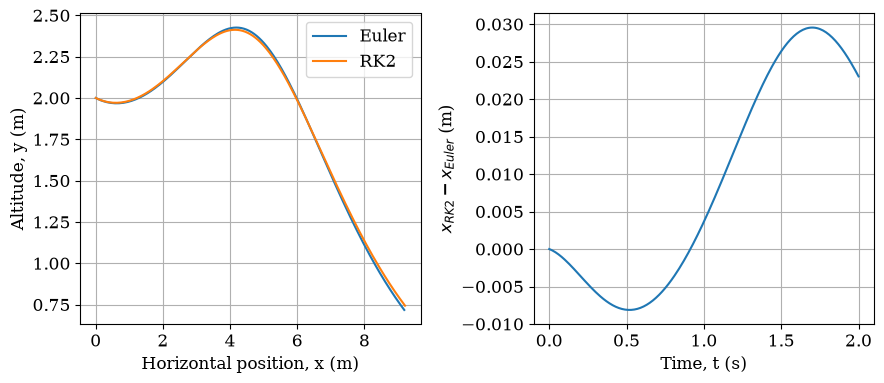

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9.0, 4.0))
for ax in axes:
    ax.grid()
    ax.set_xlabel('Horizontal position, x (m)')
    ax.set_ylabel('Altitude, y (m)')

#Plot both approximations over the common ore-impact interval.
axes[0].plot(x_euler, y_euler, label='Euler')
axes[0].plot(x_rk2, y_rk2, label='RK2')
axes[0].legend()

#Plot their horizontal separation on the same time grid.
axes[1].plot(t_trajectory, x_rk2 - x_euler)
axes[1].set_xlabel('Time, t (s)')
axes[1].set_ylabel(r'$x_{RK2} - x_{Euler}$ (m)')
fig.tight_layout()

## Examine time-step error

RK2 is run with several time-step sizes. Each position history is compared with the finest-step result using the supplied discrete L1 difference, and the plot shows how that difference changes as the step is refined.

In [12]:
#Set the time-step sizes to investigate.
dt_values = [0.1, 0.05, 0.01, 0.005, 0.001]
u_histories = []

for dt_trial in dt_values:
    num_steps_trial = int(round(T_trajectory / dt_trial))
    u_trial = np.empty((num_steps_trial + 1, 4))
    u_trial[0] = np.array([v_0, theta_0, x_0, y_0])

    for n in range(num_steps_trial):
        u_trial[n + 1] = rk2_step(
            u_trial[n], rhs_full_phugoid, dt_trial,
            C_L, C_D, g, v_t,
        )
    u_histories.append(u_trial)

In [13]:
#Compute the differences in horizontal position.
difference_values = []
for u_trial, dt_trial in zip(u_histories, dt_values, strict=True):
    difference = discrete_l1_difference(
        u_trial[:, 2], u_histories[-1][:, 2],
        dt_trial, dt_values[-1]
    )
    difference_values.append(difference)

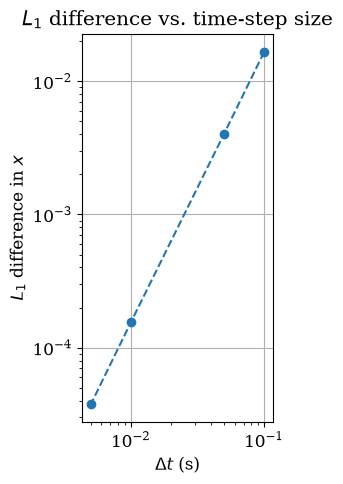

In [14]:
fig, ax = plt.subplots(figsize=(5.0, 5.0))
ax.set_title(r'$L_1$ difference vs. time-step size')
ax.set_xlabel(r'$\Delta t$ (s)')
ax.set_ylabel(r'$L_1$ difference in $x$')
ax.grid()
ax.loglog(
    dt_values[:-1], difference_values[:-1],
    color='tab:blue', linestyle='--', marker='o',
)
ax.set_aspect('equal', adjustable='box')
fig.tight_layout()

## Estimate observed convergence order

Three RK2 solutions on successively refined grids are compared. The ratio of coarse-to-medium and medium-to-fine differences estimates the observed order; a ratio near the refinement factor squared is consistent with second-order behavior in the asymptotic range.

In [15]:
refinement_ratio = 2
dt_fine = 0.001
dt_order = [
    dt_fine,
    refinement_ratio * dt_fine,
    refinement_ratio**2 * dt_fine,
]
u_order = []

for dt_trial in dt_order:
    num_steps_trial = int(round(T_trajectory / dt_trial))
    u_trial = np.empty((num_steps_trial + 1, 4))
    u_trial[0] = np.array([v_0, theta_0, x_0, y_0])

    for n in range(num_steps_trial):
        u_trial[n + 1] = rk2_step(
            u_trial[n], rhs_full_phugoid, dt_trial,
            C_L, C_D, g, v_t,
        )
    u_order.append(u_trial)

#Compare horizontal position on the three grids.
difference_coarse_medium = discrete_l1_difference(
    u_order[2][:, 2], u_order[1][:, 2],
    dt_order[2], dt_order[1]
)
difference_medium_fine = discrete_l1_difference(
    u_order[1][:, 2], u_order[0][:, 2],
    dt_order[1], dt_order[0],
)
difference_ratio = difference_coarse_medium / difference_medium_fine
observed_order = (
    np.log(difference_ratio) / np.log(refinement_ratio)
)
print(f'Coarse–medium difference: {difference_coarse_medium:.6e} m s')
print(f'Medium–fine difference:   {difference_medium_fine:.6e} m s')
print(f'Difference ratio:         {difference_ratio:.3f}')
print(f'Observed order:           p = {observed_order:.3f}')

Coarse–medium difference: 1.880804e-05 m s
Medium–fine difference:   4.695819e-06 m s
Difference ratio:         4.005
Observed order:           p = 2.002


## Interpolate the ground crossing

`locate_touchdown` estimates the touchdown time and full state by linear interpolation between two consecutive states that bracket altitude zero. This avoids using the first below-ground state as the touchdown point.

In [16]:
def locate_touchdown(t, u, t_next, u_next):
    '''Interpolate the ground crossing inside one bracketing step.

    Parameters
    ----------
    t, t_next : float
        Times at the start and end of the bracketing step.
    u, u_next : np.ndarray
        States at those times, with u[3] > 0 and u_next[3] <= 0.

    Returns
    -------
    t_touchdown : float
        Interpolated time of the crossing.
    u_touchdown : np.ndarray
        Interpolated state atthe crossing.
    '''
    alpha = u[3] / (u[3] - u_next[3])
    t_touchdown = t + alpha * (t_next - t)
    u_touchdown = u + alpha * (u_next - u)
    return t_touchdown, u_touchdown

## Build a basic range calculation

The first draft advances one time step at a time until altitude crosses zero or the time limit is reached. It demonstrates event detection, but does not yet check inputs or reject invalid numerical states.

In [17]:
def range_first_draft(step_function, u_0, f, dt, time_limit, *args):
    '''Return a status and range from a loop with no validity checks.'''
    u = np.asarray(u_0, dtype=float)
    x_initial = u[2]
    for n in range(int(np.floor(time_limit / dt))):
        u_next = step_function(u, f, dt, *args)
        if u_next[3] <= 0.0:
            t_touchdown, u_touchdown = locate_touchdown(
                n * dt, u, (n + 1) * dt, u_next
            )
            return 'touchdown', u_touchdown[2] - x_initial
        u = u_next
    return 'time_limit', None

## Probe edge cases and validate states

These cells compare a normal launch with a zero-speed launch and inspect how comparisons behave for `NaN`. `state_is_valid` then defines an explicit rule: every state value must be finite and speed must be positive. Assertions illustrate accepted and rejected examples.

In [18]:
u_baseline = np.array([v_0, theta_0, x_0, y_0])
print(range_first_draft(
    euler_step, u_baseline, rhs_full_phugoid, 0.01, 15.0, C_L, C_D, g, v_t
))

u_zero_speed = np.array([0.0, theta_0, x_0, y_0])
print(range_first_draft(
    euler_step, u_zero_speed, rhs_full_phugoid, 0.01, 15.0, C_L, C_D, g, v_t
))


('touchdown', np.float64(14.594430989594155))
('time_limit', None)


/home/jovyan/MAE 6286/phugoid.py:32: RuntimeWarning: divide by zero encountered in scalar divide
  -(g / v) * np.cos(theta) + (g / v_t**2) * v,
/home/jovyan/MAE 6286/phugoid.py:31: RuntimeWarning: invalid value encountered in sin
  -g * np.sin(theta) - (C_D / C_L) * (g / v_t**2) * v**2,
/home/jovyan/MAE 6286/phugoid.py:32: RuntimeWarning: invalid value encountered in cos
  -(g / v) * np.cos(theta) + (g / v_t**2) * v,
/home/jovyan/MAE 6286/phugoid.py:33: RuntimeWarning: invalid value encountered in cos
  v * np.cos(theta),
/home/jovyan/MAE 6286/phugoid.py:34: RuntimeWarning: invalid value encountered in sin
  v * np.sin(theta),


In [19]:
print(np.nan <= 0.0, np.nan > 0.0, np.isfinite(np.nan))

False False False


In [20]:
def state_is_valid(u):
    '''Return True when every entry is finite and the speed is positive.'''
    return np.all(np.isfinite(u)) and u[0] > 0.0

assert state_is_valid(u_baseline)
assert not state_is_valid(u_zero_speed)
assert not state_is_valid(np.array([np.nan, theta_0, x_0, y_0]))

## Integrate safely to touchdown

`integrate_until_touchdown` adds input validation, checks each new state, records accepted times and states, and returns a status plus touchdown time, state, and range when available. If the flight reaches the time limit or becomes invalid, it preserves that status and leaves the range unavailable.

In [21]:
def integrate_until_touchdown(
    step_function, u_0, f, dt, time_limit, *args
):
    '''Integrate until touchdown, the time limit, or an invalid state.'''
    if dt <= 0.0:
        raise ValueError('dt must be positive.')

    u = np.asarray(u_0, dtype=float)
    if u.shape != (4,) or u[3] <= 0.0:
        raise ValueError(
            'u_0 must contain [v, theta, x, y] with positive altitude.'
        )
    x_initial = u[2]

    max_steps = int(np.floor(time_limit / dt))
    times = [0.0]
    states = [u.copy()]
    status = 'time_limit'
    touchdown_time = None
    touchdown_state = None
    range_value = None

    for n in range(max_steps):
        u_next = step_function(u, f, dt, *args)

        if not state_is_valid(u_next):
            status = 'invalid_state'
            break

        t_next = (n + 1) * dt
        times.append(t_next)
        states.append(u_next)

        if u_next[3] <= 0.0:
            touchdown_time, touchdown_state = locate_touchdown(
                n * dt, u, t_next, u_next
            )
            range_value = touchdown_state[2] - x_initial
            status = 'touchdown'
            break

        u = u_next

    return {
        'status': status,
        'times': np.asarray(times),
        'states': np.asarray(states),
        'touchdown_time': touchdown_time,
        'touchdown_state': touchdown_state,
        'range': range_value,
        'steps': len(times) - 1,
    }

## Check integration outcomes

The examples verify that a short time limit is reported as unfinished and that a zero-speed launch is rejected as an invalid state. The following guard check confirms that an initial state already below ground raises a clear input error.

In [22]:
unfinished_result = integrate_until_touchdown(
    euler_step, u_baseline, rhs_full_phugoid,
    0.01, 0.1, C_L, C_D, g, v_t,
)
invalid_result = integrate_until_touchdown(
    euler_step, u_zero_speed, rhs_full_phugoid,
    0.01, 15.0, C_L, C_D, g, v_t,
)

for result in (unfinished_result, invalid_result):
    print(
        f'{result["status"]}: range = {result["range"]}; '
        f'{result["steps"]} accepted steps'
    )

assert unfinished_result['status'] == 'time_limit'
assert unfinished_result['range'] is None
assert unfinished_result['steps'] == 10
assert invalid_result['status'] == 'invalid_state'
assert invalid_result['range'] is None
assert invalid_result['steps'] == 0


time_limit: range = None; 10 accepted steps
invalid_state: range = None; 0 accepted steps


In [23]:
u_below_ground = np.array([v_0, theta_0, x_0, -1.0])
guard_triggered = False
try:
    integrate_until_touchdown(
        euler_step, u_below_ground, rhs_full_phugoid,
        0.01, 15.0, C_L, C_D, g, v_t,
    )
except ValueError as error:
    guard_triggered = True
    print('Rejected:', error)

assert guard_triggered


Rejected: u_0 must contain [v, theta, x, y] with positive altitude.


## Validate against steady flight

A steady glide state is constructed from the lift-to-drag ratio. Its analytic touchdown time and range provide known values for checking Euler and RK2 with several step sizes; assertions also verify that the interpolated event lies inside the bracketing step.

In [24]:
eta = C_D / C_L
theta_steady = -np.arctan(eta)
v_steady = v_t * np.sqrt(np.cos(theta_steady))
u_steady = np.array([v_steady, theta_steady, 0.0, y_0])
exact_steady_time = -y_0 / (v_steady * np.sin(theta_steady))
exact_steady_range = y_0 * C_L / C_D
verification_dts = [0.5, 0.4, 0.25]

print('method      dt (s)   touchdown (s)   range (m)   error (m)')
for method_name, step_function in (
    ('Euler', euler_step), ('RK2', rk2_step)
):
    for dt_trial in verification_dts:
        result = integrate_until_touchdown(
            step_function, u_steady, rhs_full_phugoid,
            dt_trial, 15.0, C_L, C_D, g, v_t,
        )
        assert result['status'] == 'touchdown'
        range_error = abs(result['range'] - exact_steady_range)
        print(
            f'{method_name:<8} {dt_trial:8.2f} '
            f'{result["touchdown_time"]:15.9f} '
            f'{result["range"]:11.9f} {range_error:11.3e}'
        )

        assert (
            result['times'][-2]
            < result['touchdown_time']
            < result['times'][-1]
        )
        assert abs(result['touchdown_time'] - exact_steady_time) < 1e-10
        assert range_error < 1e-10

method      dt (s)   touchdown (s)   range (m)   error (m)
Euler        0.50     2.101739684 10.000000000   3.553e-15
Euler        0.40     2.101739684 10.000000000   3.553e-15
Euler        0.25     2.101739684 10.000000000   3.553e-15
RK2          0.50     2.101739684 10.000000000   3.553e-15
RK2          0.40     2.101739684 10.000000000   0.000e+00
RK2          0.25     2.101739684 10.000000000   1.776e-15


## Compare baseline flight paths and work

Euler and RK2 integrate the baseline launch with the same time step and time limit. The results are retained by method, and right-hand-side evaluations estimate computational work: one evaluation per Euler step and two per RK2 step.

In [25]:
dt_touchdown = 0.01
time_limit = 15.0
rhs_calls_per_step = {'Euler': 1, 'RK2': 2}
flight_results = {}

for method_name, step_function in (
    ('Euler', euler_step), ('RK2', rk2_step)
):
    result = integrate_until_touchdown(
        step_function, u_baseline, rhs_full_phugoid,
        dt_touchdown, time_limit, C_L, C_D, g, v_t,
    )
    flight_results[method_name] = result
    work = result['steps'] * rhs_calls_per_step[method_name]

    if result['range'] is None:
        print(
            f'{method_name}: {result["status"]}; '
            f'range unavailable; {work} RHS evaluations'
        )
    else:
        print(
            f'{method_name}: {result["status"]}; '
            f't = {result["touchdown_time"]:.6f} s; '
            f'R = {result["range"]:.6f} m; '
            f'{work} RHS evaluations'
        )


Euler: touchdown; t = 3.089928 s; R = 14.594431 m; 309 RHS evaluations
RK2: touchdown; t = 3.073395 s; R = 14.531319 m; 616 RHS evaluations


## Plot the computed flight paths

The recorded trajectories are plotted as altitude versus horizontal position. For a touchdown, the final plotted point is replaced by the interpolated event state so the path ends at the estimated ground crossing.

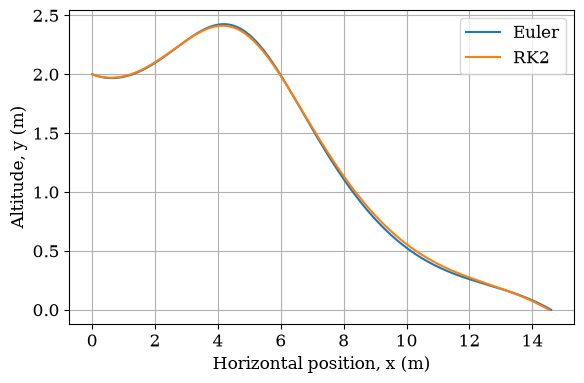

In [26]:
fig, ax = plt.subplots(figsize=(6.0, 4.0))
for method_name, result in flight_results.items():
    path = result['states'].copy()
    if result['status'] == 'touchdown':
        # Replace the below-ground bracket endpoint by the event point.
        path[-1] = result['touchdown_state']
    ax.plot(path[:, 2], path[:, 3], label=method_name)

ax.set_xlabel('Horizontal position, x (m)')
ax.set_ylabel('Altitude, y (m)')
ax.grid()
ax.legend()
fig.tight_layout()

## Establish a range reference

The RK2 step is repeatedly halved and the resulting range changes are measured. Two consecutive changes below a tolerance are required before the latest range is accepted as a reference. The selected step is also retained as `dt_search` for the launch grid.

In [28]:
range_target = 0.01  # required numerical range accuracy (m)
reference_tolerance = 0.1 * range_target  # a reference must beat the target
dt_reference = dt_touchdown
result = integrate_until_touchdown(
    rk2_step, u_baseline, rhs_full_phugoid,
    dt_reference, time_limit, C_L, C_D, g, v_t,
)
range_previous = result['range']
reference_work = result['steps'] * rhs_calls_per_step['RK2']
small_changes = 0
reference_accepted = False

print('dt (s)         range (m)    change (m)')
print(f'{dt_reference:<12.6f} {range_previous:12.6f}')
for halving in range(8):
    dt_reference = dt_reference / 2
    result = integrate_until_touchdown(
        rk2_step, u_baseline, rhs_full_phugoid,
        dt_reference, time_limit, C_L, C_D, g, v_t,
    )
    assert result['status'] == 'touchdown'
    reference_work += result['steps'] * rhs_calls_per_step['RK2']
    change = abs(result['range'] - range_previous)
    print(f'{dt_reference:<12.6f} {result["range"]:12.6f} {change:12.3e}')
    range_previous = result['range']

    if change < reference_tolerance:
        small_changes += 1
    else:
        small_changes = 0
    if small_changes == 2:
        reference_accepted = True
        break

assert reference_accepted, 'Insufficient evidence for a range reference.'
range_reference = range_previous
dt_search = dt_reference
print(f'Reference range: {range_reference:.6f} m at dt_search = {dt_search:g} s')
print(f'Work to establish the reference: {reference_work} RHS evaluations')

dt (s)         range (m)    change (m)
0.010000        14.531319
0.005000        14.531054    2.651e-04
0.002500        14.530989    6.486e-05
Reference range: 14.530989 m at dt_search = 0.0025 s
Work to establish the reference: 4306 RHS evaluations


***Agent launch-search task brief***
**Goal and scope**

Add two readable, unexecuted Python cells below this brief in [Clase 5 Code]. Cell 1 searches a grid of launches. Cell 2 checks the leading launches. Leave the choice of launch and all conclusions to me.

**Non-negotiables**

Reuse rk2_step(), rhs_full_phugoid(), integrate_until_touchdown(), the model parameters, the release point, and the 15 s time limit already in the notebook. Use the notebook variable dt_search, whose value is [0.002500]. Use ordinary loops and comments. Report angles in degrees and convert to radians only when building a state.

Cell 1, the search:

Run RK2 at dt_search for all 17 equally spaced speeds from 4 to 12 m/s and all 25 equally spaced angles from 
−
3
0
∘
−30 
∘
  to 
3
0
∘
30 
∘
 , endpoints included: 425 launches.

Keep one record per launch: speed, angle in degrees, range, status, and step count. A failed or unfinished run keeps range=None and is never ranked.

Print the count of each status, then the five largest ranges with their speed and angle. Keep all records in a list for Cell 2. If fewer than five runs succeed, print that instead and stop.

Cell 2, the checks:

Time step: rerun the five best launches at dt_search/2. For each, print the range and status at both steps and the change between successful results.

Nearby launches: around the best launch from Cell 1, change only the angle by 
−
1.2
5
∘
−1.25 
∘
  and 
+
1.2
5
∘
+1.25 
∘
 , then only the speed by -0.25 and +0.25 m/s. Skip any point outside the original bounds. Run these checks at dt_search/2. Print each range and its signed change from the center launch at that same step; positive means farther.

Retain all check records and statuses. Failed or unfinished checks keep None for range and change.

Print results only. Do not rank, choose, or comment on them.

**Allowed actions**

Read the attached notebook and add only these two cells. The following are disallowed: changing existing cells, redefining the model or numerical functions, running code, creating files, downloading anything, accessing the network, or installing packages.

**Done when**

Both cells are inserted, without outputs or execution counts. Stop and report where they were added and which variables they create. I will inspect and run them.

## Search launch speed and angle

This grid evaluates 17 speeds and 25 angles with RK2 at `dt_search`. Every launch retains its speed, angle, status, and step count; only successful touchdowns receive a range and are eligible for the five largest sampled ranges.

In [29]:
# Search the 425 launches using the existing model and release point.
launch_speeds = np.linspace(4.0, 12.0, 17)
launch_angles_deg = np.linspace(-30.0, 30.0, 25)
launch_records = []
launch_status_counts = {'touchdown': 0, 'time_limit': 0, 'invalid_state': 0}
launch_successes = []
launch_top_five = []

for launch_speed in launch_speeds:
    for launch_angle_deg in launch_angles_deg:
        launch_state = np.array([
            launch_speed, np.deg2rad(launch_angle_deg), x_0, y_0
        ])
        launch_result = integrate_until_touchdown(
            rk2_step, launch_state, rhs_full_phugoid,
            dt_search, time_limit, C_L, C_D, g, v_t,
        )
        launch_record = {
            'speed': float(launch_speed),
            'angle_deg': float(launch_angle_deg),
            'range': None,
            'status': launch_result['status'],
            'steps': launch_result['steps'],
        }
        if launch_result['status'] == 'touchdown':
            launch_record['range'] = launch_result['range']
        launch_records.append(launch_record)
        launch_status_counts[launch_record['status']] = (
            launch_status_counts.get(launch_record['status'], 0) + 1
        )
        if (launch_record['status'] == 'touchdown'
                and launch_record['range'] is not None):
            launch_successes.append(launch_record)

for launch_status, launch_count in launch_status_counts.items():
    print(f'{launch_status}: {launch_count}')

# Leave the leading-launch list empty if the checks cannot proceed.
if len(launch_successes) < 5:
    print(f'Only {len(launch_successes)} launches succeeded; stopping.')
else:
    launch_top_five = sorted(
        launch_successes, key=lambda record: record['range'], reverse=True
    )[:5]
    print('Five largest ranges: speed (m/s), angle (deg), range (m)')
    for launch_record in launch_top_five:
        print(
            f"{launch_record['speed']:.2f}  "
            f"{launch_record['angle_deg']:+.2f}  "
            f"{launch_record['range']:.6f}"
        )


touchdown: 425
time_limit: 0
invalid_state: 0
Five largest ranges: speed (m/s), angle (deg), range (m)
10.00  -17.50  18.044836
10.00  -20.00  18.042290
10.00  -15.00  18.030818
10.00  -22.50  18.023977
10.50  -20.00  18.001817


## Check leading and nearby launches

The five leading grid launches are rerun with half the search step, then four nearby launches vary one parameter at a time around the grid leader. Records retain statuses and ranges, while signed changes show how the nearby results compare with the center at the same step.

In [30]:
# Check the five leaders in their Cell 1 order; do not rank the checks.
check_dt = dt_search / 2.0
check_time_records = []
check_nearby_records = []
check_center = None
check_center_range = None
check_neighbors = []

if len(launch_top_five) < 5:
    print('Fewer than five successful grid launches; checks stopped.')
else:
    for check_launch in launch_top_five:
        check_state = np.array([
            check_launch['speed'], np.deg2rad(check_launch['angle_deg']),
            x_0, y_0,
        ])
        check_result = integrate_until_touchdown(
            rk2_step, check_state, rhs_full_phugoid,
            check_dt, time_limit, C_L, C_D, g, v_t,
        )
        check_range = None
        check_change = None
        if check_result['status'] == 'touchdown':
            check_range = check_result['range']
        if check_range is not None and check_launch['range'] is not None:
            check_change = check_range - check_launch['range']
        check_record = {
            'speed': check_launch['speed'],
            'angle_deg': check_launch['angle_deg'],
            'coarse_dt': dt_search,
            'coarse_range': check_launch['range'],
            'coarse_status': check_launch['status'],
            'coarse_steps': check_launch['steps'],
            'dt': check_dt,
            'range': check_range,
            'status': check_result['status'],
            'steps': check_result['steps'],
            'change': check_change,
        }
        check_time_records.append(check_record)
        print(
            f"speed={check_record['speed']:.2f} m/s, "
            f"angle={check_record['angle_deg']:+.2f} deg: "
            f"dt={dt_search:g} s, range={check_launch['range']} m, "
            f"status={check_launch['status']}; "
            f"dt={check_dt:g} s, range={check_range} m, "
            f"status={check_result['status']}; "
            f"change (fine - coarse)={check_change} m"
        )

    # Use the same-step center result already retained above.
    check_center = check_time_records[0]
    check_center_range = check_center['range']
    check_neighbors = [
        (check_center['speed'], check_center['angle_deg'] - 1.25),
        (check_center['speed'], check_center['angle_deg'] + 1.25),
        (check_center['speed'] - 0.25, check_center['angle_deg']),
        (check_center['speed'] + 0.25, check_center['angle_deg']),
    ]
    for check_speed, check_angle_deg in check_neighbors:
        if not (4.0 <= check_speed <= 12.0
                and -30.0 <= check_angle_deg <= 30.0):
            continue
        check_state = np.array([
            check_speed, np.deg2rad(check_angle_deg), x_0, y_0
        ])
        check_result = integrate_until_touchdown(
            rk2_step, check_state, rhs_full_phugoid,
            check_dt, time_limit, C_L, C_D, g, v_t,
        )
        check_range = None
        check_change = None
        if check_result['status'] == 'touchdown':
            check_range = check_result['range']
        if check_range is not None and check_center_range is not None:
            check_change = check_range - check_center_range
        check_record = {
            'speed': check_speed,
            'angle_deg': check_angle_deg,
            'dt': check_dt,
            'range': check_range,
            'status': check_result['status'],
            'steps': check_result['steps'],
            'center_range': check_center_range,
            'center_status': check_center['status'],
            'change': check_change,
        }
        check_nearby_records.append(check_record)
        check_change_text = (
            'None' if check_change is None else f'{check_change:+.6f}'
        )
        print(
            f"speed={check_speed:.2f} m/s, angle={check_angle_deg:+.2f} deg: "
            f"dt={check_dt:g} s, range={check_range} m, "
            f"status={check_result['status']}; "
            f"change (neighbor - center; positive means farther)="
            f"{check_change_text} m"
        )


speed=10.00 m/s, angle=-17.50 deg: dt=0.0025 s, range=18.04483564841139 m, status=touchdown; dt=0.00125 s, range=18.04485234184945 m, status=touchdown; change (fine - coarse)=1.669343805943413e-05 m
speed=10.00 m/s, angle=-20.00 deg: dt=0.0025 s, range=18.042290421670963 m, status=touchdown; dt=0.00125 s, range=18.04230723050021 m, status=touchdown; change (fine - coarse)=1.6808829247594304e-05 m
speed=10.00 m/s, angle=-15.00 deg: dt=0.0025 s, range=18.030817815476713 m, status=touchdown; dt=0.00125 s, range=18.03083224960562 m, status=touchdown; change (fine - coarse)=1.443412890722584e-05 m
speed=10.00 m/s, angle=-22.50 deg: dt=0.0025 s, range=18.023977080766425 m, status=touchdown; dt=0.00125 s, range=18.02399855332513 m, status=touchdown; change (fine - coarse)=2.147255870355025e-05 m
speed=10.50 m/s, angle=-20.00 deg: dt=0.0025 s, range=18.00181741875355 m, status=touchdown; dt=0.00125 s, range=18.001830534750926 m, status=touchdown; change (fine - coarse)=1.3115997376189625e-05 m

## Refine a candidate launch

A candidate speed and angle are evaluated at progressively smaller RK2 steps. The finest computed range becomes `range_reference_candidate`, while the table reports changes between successive refinements and the total RHS evaluation work.

In [31]:
v_candidate = 10            # m/s
theta_candidate_deg = -17.5    # degrees
u_candidate = np.array([
    v_candidate, np.deg2rad(theta_candidate_deg), x_0, y_0
])

print('dt (s)         range (m)    change (m)')
range_previous = None
reference_work_candidate = 0
range_reference_candidate = None
for dt_trial in (dt_search, dt_search / 2, dt_search / 4):
    result = integrate_until_touchdown(
        rk2_step, u_candidate, rhs_full_phugoid,
        dt_trial, time_limit, C_L, C_D, g, v_t,
    )
    assert result['status'] == 'touchdown'
    reference_work_candidate += result['steps'] * rhs_calls_per_step['RK2']
    if range_previous is None:
        print(f'{dt_trial:<12.6f} {result["range"]:12.6f}')
    else:
        change = abs(result['range'] - range_previous)
        assert change < reference_tolerance
        print(f'{dt_trial:<12.6f} {result["range"]:12.6f} {change:12.3e}')
    range_previous = result['range']

range_reference_candidate = range_previous
print(f'Candidate reference work: {reference_work_candidate} RHS evaluations')

dt (s)         range (m)    change (m)
0.002500        18.044836
0.001250        18.044852    1.669e-05
0.000625        18.044856    3.912e-06
Candidate reference work: 23288 RHS evaluations



***Agent candidate-comparison task brief***
**Goal and scope**

Add one readable, unexecuted Python cell immediately below this brief. It applies a method comparison (Euler vs. midpoint Runge-Kutta) to u_candidate, using range_reference_candidate as the reference. Report the table; leave conclusions to me.

**Non-negotiables**

Reuse the existing model, step functions, touchdown evaluator, parameters, release point, and 15 s time limit. Use ordinary loops and comments. Leave range_reference, dt_search, and range_reference_candidate unchanged.

For each method, start at a time step of 0.1 s and halve it repeatedly, at most 12 times. A run qualifies when its computed range differs from range_reference_candidate by at most range_target. Stop halving the time step after the first qualifying run and one finer run that also qualifies with a smaller difference. If that does not happen within 12 halvings, report insufficient evidence for that method.

Print one row per run: method, time step, range, absolute difference from the reference, completed steps, RHS evaluations, and status. A failed or unfinished run keeps its status and work, shows None for range and difference, and never qualifies.

Count computational work as result['steps'] * rhs_calls_per_step[method_name].

**Allowed actions**

Read the attached notebook and add only this cell. Disallowed: change existing cells, redefine numerical functions, run code, create files, download anything, access the network, or install packages. Do not say which method is better.

**Done when**

The cell is inserted, without output or execution count. Stop and report where it was added and which variables it creates. If anything in this brief is unclear, say so instead of guessing.

## Compare Euler and RK2 with the candidate reference

Each method starts at a 0.1-second step and halves it up to twelve times. A run qualifies when its range is within `range_target` of the candidate reference; a finer qualifying run with a smaller difference confirms the evidence. Every run reports range, difference, steps, work, and status, while failed or unfinished runs cannot qualify.

In [32]:
# Compare both methods for the existing candidate and reference.
print(
    'method   dt (s)         range (m)       abs. difference (m)  '
    'steps   RHS evaluations  status'
)
for comparison_method, comparison_step in (
    ('Euler', euler_step), ('RK2', rk2_step)
):
    comparison_first_difference = None
    comparison_confirmed = False

    # Include the initial run and at most twelve halvings (13 runs).
    for comparison_halving in range(13):
        comparison_dt = 0.1 / (2 ** comparison_halving)
        comparison_result = integrate_until_touchdown(
            comparison_step, u_candidate, rhs_full_phugoid,
            comparison_dt, time_limit, C_L, C_D, g, v_t,
        )
        comparison_work = (
            comparison_result['steps'] * rhs_calls_per_step[comparison_method]
        )
        comparison_range = None
        comparison_difference = None
        comparison_qualifies = False
        if (comparison_result['status'] == 'touchdown'
                and comparison_result['range'] is not None):
            comparison_range = comparison_result['range']
            comparison_difference = abs(
                comparison_range - range_reference_candidate
            )
            comparison_qualifies = comparison_difference <= range_target

        comparison_range_text = (
            'None' if comparison_range is None
            else f'{comparison_range:.9f}'
        )
        comparison_difference_text = (
            'None' if comparison_difference is None
            else f'{comparison_difference:.6e}'
        )
        print(
            f'{comparison_method:<8} {comparison_dt:<14.9g} '
            f'{comparison_range_text:>14} '
            f'{comparison_difference_text:>20} '
            f"{comparison_result['steps']:7d} {comparison_work:17d}  "
            f"{comparison_result['status']}"
        )

        # Retain the first qualifying difference, then seek a finer
        # qualifying run whose difference is strictly smaller.
        if comparison_qualifies:
            if comparison_first_difference is None:
                comparison_first_difference = comparison_difference
            elif comparison_difference < comparison_first_difference:
                comparison_confirmed = True
                break

    if not comparison_confirmed:
        print(f'{comparison_method}: insufficient evidence within 12 halvings.')


method   dt (s)         range (m)       abs. difference (m)  steps   RHS evaluations  status
Euler    0.1                      None                 None      10                10  invalid_state
Euler    0.05             15.900994919         2.143861e+00      81                81  touchdown
Euler    0.025            16.991279328         1.053577e+00     163               163  touchdown
Euler    0.0125           17.527366193         5.174901e-01     329               329  touchdown
Euler    0.00625          17.788689790         2.561665e-01     661               661  touchdown
Euler    0.003125         17.917458405         1.273978e-01    1327              1327  touchdown
Euler    0.0015625        17.981334292         6.352196e-02    2657              2657  touchdown
Euler    0.00078125       18.013139992         3.171626e-02    5318              5318  touchdown
Euler    0.000390625      18.029009787         1.584647e-02   10640             10640  touchdown
Euler    0.0001953125     18.0